# Task: Sentence-Embedding Model Comparison

Compare three off-the-shelf sentence-transformer models and cache their embeddings
for both standardized corpora (Coarse Discourse and CGA-CMV).

Models compared:
- `all-MiniLM-L6-v2` (384 dims, smallest and fastest)
- `BAAI/bge-small-en-v1.5` (384 dims, longest input limit)
- `all-mpnet-base-v2` (768 dims, largest)

Synthetic placeholder utterances (inserted during standardization to repair missing
parents) are excluded everywhere. Empty and deleted utterances are cached with flags
but left out of the evaluations below.

## Approach

Encoding all ~159k utterances with three models takes about four hours on a CPU, so the
comparison runs on a reproducible random sample of whole conversations from each corpus
(~7% of Coarse Discourse threads, ~15% of CGA-CMV pairs). The winning model is then run
on the full corpora with `artifacts/embeddings.py`.

Each model is judged on:
1. **Discourse-act classification** (Coarse Discourse): logistic regression on the
   embeddings, 5-fold cross-validation grouped by conversation. Compared against the
   TF-IDF baseline from notebook 04 on the same folds.
2. **Derailment forecasting** (CGA-CMV): predict whether a thread ends in a removed
   comment from the mean embedding of every comment *before* the last one. Folds are
   grouped by `pair_id`, so a thread and its matched partner never span train and test.
3. **Clustering**: silhouette score of KMeans clusters (topic-discovery use case).
4. **Practical cost**: encoding speed, vector size, and how many texts get truncated.
5. **Nearest neighbours**: a qualitative look at what each model treats as similar.

In [12]:
from pathlib import Path
import sys

current = Path.cwd()

if (current / "artifacts").exists():
    repo_root = current
else:
    repo_root = current.parent

sys.path.insert(0, str(repo_root / "artifacts"))

import numpy as np
import pandas as pd

from embeddings import (
    CANDIDATE_MODELS, CORPORA, DEFAULT_CACHE_ROOT, SentenceTransformerEmbedder,
    build_text_table, cache_dir, embed_and_cache, load_cache, sample_conversations,
)
from standardize_convokit import iter_standardized

MODELS = list(CANDIDATE_MODELS)
CACHE_ROOT = repo_root / DEFAULT_CACHE_ROOT / "comparison"
SAMPLE_FRACTION = {"coarse-discourse": 0.07, "cga-cmv": 0.15}

print("Models:", MODELS)
print("Cache:", CACHE_ROOT.relative_to(repo_root))

Models: ['all-MiniLM-L6-v2', 'all-mpnet-base-v2', 'BAAI/bge-small-en-v1.5']
Cache: data\local\embeddings\comparison


## Build the samples

Conversations are kept or dropped by hashing an ID (the same hashing as
`corpora.split_by_group`), so every run picks the same sample. CGA-CMV is sampled by
`pair_id`, which keeps each derailed thread together with its matched non-derailed
partner and keeps the sample balanced.

In [13]:
def pair_id(conversation):
    return conversation.metadata["source_metadata"]["pair_id"]

sampled = {
    "coarse-discourse": list(sample_conversations(
        iter_standardized(repo_root / CORPORA["coarse-discourse"]),
        SAMPLE_FRACTION["coarse-discourse"],
    )),
    "cga-cmv": list(sample_conversations(
        iter_standardized(repo_root / CORPORA["cga-cmv"]),
        SAMPLE_FRACTION["cga-cmv"],
        key=pair_id,
    )),
}
tables = {corpus: build_text_table(convs) for corpus, convs in sampled.items()}

for corpus, table in tables.items():
    n_synthetic = sum(
        u.metadata.get("is_synthetic", False) for c in sampled[corpus] for u in c.utterances
    )
    print(f"{corpus}: {len(sampled[corpus])} conversations, {len(table)} utterances "
          f"({n_synthetic} synthetic excluded, {table.is_empty.sum()} empty, "
          f"{table.is_deleted.sum()} deleted)")

coarse-discourse: 655 conversations, 8051 utterances (15 synthetic excluded, 205 empty, 88 deleted)
cga-cmv: 990 conversations, 6316 utterances (0 synthetic excluded, 0 empty, 168 deleted)


## Encode and cache

Each (model, corpus) pair is cached under `data/local/embeddings/comparison/`. Rerunning
the notebook loads the cache instead of encoding again; delete that folder to force a
fresh run.

In [14]:
def get_embeddings(model_name, corpus):
    directory = cache_dir(model_name, corpus, root=CACHE_ROOT)
    if not (directory / "manifest.json").exists():
        embedder = SentenceTransformerEmbedder(model_name)
        embed_and_cache(
            corpus, embedder, root=CACHE_ROOT, table=tables[corpus],
            extra_manifest={"sample_fraction": SAMPLE_FRACTION[corpus]},
        )
    cached = load_cache(directory)
    # The cache must describe exactly this sample, row for row.
    assert list(cached.ids.utterance_id) == list(tables[corpus].utterance_id)
    return cached

cached = {(m, c): get_embeddings(m, c) for m in MODELS for c in tables}
print("Loaded", len(cached), "caches")

Loaded 6 caches


## Practical cost

Speed is CPU encoding time from each cache's manifest. *Truncated* counts texts longer than
the model's token limit; anything past the limit is ignored when encoding. Storage is
float32 size per 100k utterances (half that with `--dtype float16`).

In [15]:
cost_rows = []
for m in MODELS:
    embedder = SentenceTransformerEmbedder(m)
    row = {
        "model": m,
        "dim": CANDIDATE_MODELS[m],
        "max_tokens": embedder.max_seq_length,
        "MB per 100k": CANDIDATE_MODELS[m] * 4 * 100_000 / 1e6,
    }
    for c, table in tables.items():
        manifest = cached[(m, c)].manifest
        row[f"{c} sec/1k"] = round(1000 * manifest["encode_seconds"] / manifest["n_rows"], 1)
        row[f"{c} truncated %"] = round(100 * embedder.count_truncated(table.text.tolist()) / len(table), 1)
    cost_rows.append(row)

cost = pd.DataFrame(cost_rows).set_index("model")
cost

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3469.54it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (646 > 256). Running this sequence through the model will result in indexing errors
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1135.63it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (646 > 384). Running this sequence through the model will result in indexing errors
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2407.06it/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (646 > 512). Running this sequence through the model will result in indexing errors


,dim,max_tokens,MB per 100k,coarse-discourse sec/1k,coarse-discourse truncated %,cga-cmv sec/1k,cga-cmv truncated %
model,,,,,,,
all-MiniLM-L6-v2,384,256,153.6,4.5,3.4,6.4,12.9
all-mpnet-base-v2,768,384,307.2,35.2,1.8,60.4,6.2
BAAI/bge-small-en-v1.5,384,512,153.6,12.3,1.0,21.7,3.5


## Test 1: discourse-act classification (Coarse Discourse)

Same filtering as notebook 04: labeled, non-empty utterances, excluding `other`.
Class-balanced logistic regression, because macro-F1 is the metric and the labels
are very imbalanced (`answer` is ~42%). Folds are grouped by conversation so no
thread is split across train and test.

In [16]:
from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold

from evaluation import classification_metrics

cd = tables["coarse-discourse"]
mask = (cd.discourse_act.notna() & (cd.discourse_act != "other") & ~cd.is_empty).to_numpy()
labeled = cd[mask].reset_index(drop=True)
y = labeled.discourse_act.to_numpy()
folds = list(GroupKFold(n_splits=5).split(labeled, y, groups=labeled.conversation_id))
print(len(labeled), "labeled utterances")
print(Counter(y).most_common())

def cross_validate(featurize, make_model):
    fold_f1, oof = [], np.empty(len(y), dtype=object)
    for train, test in folds:
        X_train, X_test = featurize(train, test)
        model = make_model().fit(X_train, y[train])
        oof[test] = model.predict(X_test)
        fold_f1.append(classification_metrics(y[test], oof[test]).macro_f1)
    return fold_f1, oof

def balanced_lr():
    return LogisticRegression(max_iter=2000, class_weight="balanced")

def tfidf_features(train, test):
    vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=100_000)
    return vectorizer.fit_transform(labeled.text[train]), vectorizer.transform(labeled.text[test])

def embedding_features(model_name):
    X = np.asarray(cached[(model_name, "coarse-discourse")].embeddings)[mask]
    return lambda train, test: (X[train], X[test])

class Majority:
    def fit(self, X, y_train):
        self.label = Counter(y_train).most_common(1)[0][0]
        return self
    def predict(self, X):
        return np.array([self.label] * X.shape[0])

runs = {"majority": (tfidf_features, Majority), "tfidf + LR": (tfidf_features, balanced_lr)}
runs.update({m: (embedding_features(m), balanced_lr) for m in MODELS})

clf_results, oof_preds = {}, {}
for name, (featurize, make_model) in runs.items():
    fold_f1, oof_preds[name] = cross_validate(featurize, make_model)
    pooled = classification_metrics(y, oof_preds[name])
    clf_results[name] = {
        "macro F1": np.mean(fold_f1), "± std": np.std(fold_f1),
        "accuracy": pooled.accuracy, "weighted F1": pooled.weighted_f1,
    }

clf_table = pd.DataFrame(clf_results).T.round(3)
clf_table

6848 labeled utterances
[('answer', 2903), ('elaboration', 1256), ('question', 1091), ('appreciation', 636), ('agreement', 347), ('disagreement', 236), ('humor', 185), ('negativereaction', 108), ('announcement', 86)]


,macro F1,± std,accuracy,weighted F1
majority,0.066,0.002,0.424,0.252
tfidf + LR,0.330,0.015,0.442,0.455
all-MiniLM-L6-v2,0.273,0.007,0.324,0.346
all-mpnet-base-v2,0.311,0.019,0.372,0.393
BAAI/bge-small-en-v1.5,0.311,0.019,0.367,0.385


Per-class F1 (out-of-fold predictions pooled across the five folds):

In [17]:
per_class = pd.DataFrame({
    name: classification_metrics(y, oof_preds[name]).per_class_f1
    for name in ["tfidf + LR", *MODELS]
}).round(3)
per_class["support"] = pd.Series(Counter(y))
per_class.sort_values("support", ascending=False)

,tfidf + LR,all-MiniLM-L6-v2,all-mpnet-base-v2,BAAI/bge-small-en-v1.5,support
answer,0.528,0.406,0.465,0.391,2903
elaboration,0.288,0.192,0.226,0.225,1256
question,0.561,0.356,0.410,0.574,1091
appreciation,0.630,0.561,0.576,0.594,636
agreement,0.307,0.255,0.321,0.264,347
disagreement,0.186,0.185,0.215,0.209,236
humor,0.165,0.243,0.291,0.212,185
negativereaction,0.155,0.173,0.180,0.211,108
announcement,0.161,0.100,0.119,0.125,86


## Test 2: derailment forecasting (CGA-CMV)

Each thread is represented by the mean embedding of its comments, **excluding the final
comment** (by timestamp). In CGA-CMV the final comment is the one that was removed or its
matched counterpart, so including it would leak the label. Deleted and empty comments are
also dropped from the average, since deletion itself is a leaky signal (see
`structural_features.LEAKY_FEATURES`). The sample is balanced, so chance is 0.5.

In [18]:
from sklearn.metrics import accuracy_score, roc_auc_score

cmv = tables["cga-cmv"]
last_ids, thread_labels, thread_pairs = set(), {}, {}
for conversation in sampled["cga-cmv"]:
    real = [u for u in conversation.utterances if not u.metadata.get("is_synthetic")]
    last_ids.add(max(real, key=lambda u: u.created_at).id)
    thread_labels[conversation.id] = conversation.metadata["source_metadata"]["has_removed_comment"]
    thread_pairs[conversation.id] = pair_id(conversation)

keep = (~cmv.utterance_id.isin(last_ids) & ~cmv.is_empty & ~cmv.is_deleted).to_numpy()
kept = cmv[keep]
thread_ids = sorted(set(kept.conversation_id))
y_thread = np.array([thread_labels[t] for t in thread_ids])
groups = [thread_pairs[t] for t in thread_ids]
thread_folds = list(GroupKFold(n_splits=5).split(thread_ids, y_thread, groups=groups))
print(len(thread_ids), "threads,", int(y_thread.sum()), "derailed")

def thread_cv(X):
    accs, aucs = [], []
    for train, test in thread_folds:
        model = LogisticRegression(max_iter=2000).fit(X[train], y_thread[train])
        accs.append(accuracy_score(y_thread[test], model.predict(X[test])))
        aucs.append(roc_auc_score(y_thread[test], model.predict_proba(X[test])[:, 1]))
    return {"accuracy": np.mean(accs), "ROC AUC": np.mean(aucs), "AUC ± std": np.std(aucs)}

derail_results = {}
thread_text = kept.groupby("conversation_id").text.apply(" ".join).loc[thread_ids]
X_tfidf = TfidfVectorizer(min_df=2, max_features=50_000).fit_transform(thread_text)
derail_results["tfidf + LR"] = thread_cv(X_tfidf)

for m in MODELS:
    vectors = pd.DataFrame(np.asarray(cached[(m, "cga-cmv")].embeddings)[keep])
    vectors["conversation_id"] = kept.conversation_id.to_numpy()
    X = vectors.groupby("conversation_id").mean().loc[thread_ids].to_numpy()
    derail_results[m] = thread_cv(X)

derail_table = pd.DataFrame(derail_results).T.round(3)
derail_table

990 threads, 495 derailed


,accuracy,ROC AUC,AUC ± std
tfidf + LR,0.528,0.555,0.026
all-MiniLM-L6-v2,0.532,0.557,0.011
all-mpnet-base-v2,0.548,0.585,0.021
BAAI/bge-small-en-v1.5,0.542,0.567,0.032


Note: TF-IDF is fit on all sampled threads before cross-validation, which lets it see
the vocabulary of the test folds. This flatters the baseline slightly; it is a reference
point, not a tuned competitor.

## Test 3: clustering

KMeans with k=10 on the non-empty, non-deleted utterances of each corpus, scored with the
silhouette coefficient (higher means tighter, better-separated clusters). Treat this as a
weak signal: silhouette values are not strictly comparable between embedding spaces with
different dimensions and similarity distributions.

In [19]:
from sklearn.cluster import KMeans

from evaluation import clustering_metrics

cluster_results = {}
for m in MODELS:
    row = {}
    for c, table in tables.items():
        usable = (~table.is_empty & ~table.is_deleted).to_numpy()
        X = np.asarray(cached[(m, c)].embeddings)[usable]
        labels = KMeans(n_clusters=10, n_init=10, random_state=0).fit_predict(X)
        row[f"{c} silhouette"] = clustering_metrics(X, labels).silhouette
    cluster_results[m] = row

cluster_table = pd.DataFrame(cluster_results).T.round(3)
cluster_table

,coarse-discourse silhouette,cga-cmv silhouette
all-MiniLM-L6-v2,0.019,0.028
all-mpnet-base-v2,0.018,0.024
BAAI/bge-small-en-v1.5,0.019,0.024


## Nearest neighbours

For two sample comments, the three most similar other comments according to each model
(cosine similarity; the vectors are normalized, so this is a dot product).

In [20]:
usable = (~cd.is_empty & ~cd.is_deleted).to_numpy()
pool = cd[usable].reset_index(drop=True)
word_counts = pool.text.str.split().str.len()
queries = [
    pool[(pool.discourse_act == "question") & word_counts.between(8, 30)].index[0],
    pool[(pool.discourse_act == "disagreement") & word_counts.between(8, 30)].index[0],
]

def short(text, n=110):
    text = " ".join(text.split())
    return text if len(text) <= n else text[:n] + "..."

for q in queries:
    print(f"QUERY [{pool.discourse_act[q]}]: {short(pool.text[q])}")
    for m in MODELS:
        X = np.asarray(cached[(m, "coarse-discourse")].embeddings)[usable]
        scores = X @ X[q]
        scores[q] = -np.inf
        print(f"  {m}")
        for i in np.argsort(-scores)[:3]:
            print(f"    {scores[i]:.2f} [{pool.discourse_act[i]}] {short(pool.text[i])}")
    print()

QUERY [question]: Isn't Silencio in the middle of a desert?
  all-MiniLM-L6-v2
    0.38 [humor] you know its in the middle of a dessert... its beside the Eiffel tower !
    0.36 [question] I'm currently writing a story, and I want the character to be dropped off at a place. Though this place has to...
    0.34 [answer] True, as long as they're healthy. I once lived in Tucson, and if you had a Saguaro cactus on your property it ...
  all-mpnet-base-v2
    0.49 [humor] you know its in the middle of a dessert... its beside the Eiffel tower !
    0.35 [disagreement] Not true! There is actually a rainforest where I live! :)
    0.33 [answer] I'd give up my lawn in a heartbeat for something like that. I am however a fan of all sorts of desert plants.
  BAAI/bge-small-en-v1.5
    0.63 [answer] Middle of the forest.
    0.60 [disagreement] Not true! There is actually a rainforest where I live! :)
    0.60 [disagreement] I don't think it's the 1st anywhere on the planet.

QUERY [disagreement]: 

## Summary

In [21]:
summary = pd.DataFrame({
    "discourse macro F1": clf_table["macro F1"],
    "derailment AUC": derail_table["ROC AUC"],
}).join(cluster_table).join(cost[["dim", "coarse-discourse sec/1k", "cga-cmv truncated %"]])
summary.loc[["majority", "tfidf + LR", *MODELS]]

,discourse macro F1,derailment AUC,coarse-discourse silhouette,cga-cmv silhouette,dim,coarse-discourse sec/1k,cga-cmv truncated %
majority,0.066,NaN,NaN,NaN,NaN,NaN,NaN
tfidf + LR,0.330,0.555,NaN,NaN,NaN,NaN,NaN
all-MiniLM-L6-v2,0.273,0.557,0.019,0.028,384.0,4.5,12.9
all-mpnet-base-v2,0.311,0.585,0.018,0.024,768.0,35.2,6.2
BAAI/bge-small-en-v1.5,0.311,0.567,0.019,0.024,384.0,12.3,3.5


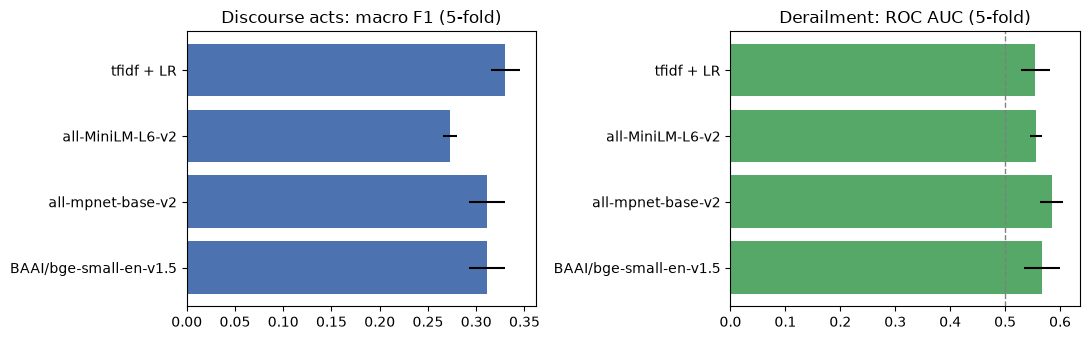

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
order = ["tfidf + LR", *MODELS]
axes[0].barh(order, clf_table.loc[order, "macro F1"], xerr=clf_table.loc[order, "± std"], color="#4C72B0")
axes[0].set_title("Discourse acts: macro F1 (5-fold)")
axes[1].barh(order, derail_table.loc[order, "ROC AUC"], xerr=derail_table.loc[order, "AUC ± std"], color="#55A868")
axes[1].axvline(0.5, color="grey", linestyle="--", linewidth=1)
axes[1].set_title("Derailment: ROC AUC (5-fold)")
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Results

Sample: 655 Coarse Discourse threads (8,051 utterances, 6,848 used for classification) and
990 CGA-CMV threads (495 matched pairs, 6,316 utterances).

| | Discourse macro F1 | Derailment AUC | CPU sec / 1k (CD) | Dim | CMV truncated |
|---|---|---|---|---|---|
| TF-IDF + LR (reference) | **0.330** | 0.555 | – | – | – |
| all-MiniLM-L6-v2 | 0.273 | 0.557 | **4.5** | 384 | 12.9% |
| all-mpnet-base-v2 | 0.311 | **0.585** | 35.2 | 768 | 6.2% |
| BAAI/bge-small-en-v1.5 | 0.311 | 0.567 | 12.3 | 384 | **3.5%** |

What the numbers say:

- **Discourse acts: embeddings alone do not beat TF-IDF.** The best models reach 0.311 macro F1
  against 0.330 for TF-IDF. Discourse acts depend on surface cues (question marks, "thanks",
  "I agree") that TF-IDF picks up directly, while sentence embeddings mostly encode *topic*.
  Embeddings do better than TF-IDF on the rarer, tone-based classes (`humor`, `negativereaction`,
  `disagreement`), so combining the two feature sets is a promising next experiment.
- **mpnet and bge-small tie on discourse acts** (0.311 each, fold std ~0.02); MiniLM is clearly
  behind (0.273).
- **Derailment is hard for every model** (AUC 0.56–0.59, where 0.5 is chance). mpnet is best,
  but its lead over bge-small (0.585 vs 0.567) is within one fold standard deviation.
- **Clustering does not separate the models**: silhouette is ~0.02 for all of them. These
  short Reddit comments do not form tight clusters at k=10 with any model, so topic discovery
  will need a better clustering setup (e.g. UMAP + HDBSCAN) rather than a different encoder.
- **Nearest neighbours** look topically sensible for all three. bge-small's cosine scores
  sit much higher (0.6–0.8) than the others' (0.3–0.5), so similarity thresholds are
  model-specific and must not be reused across models.

## Recommendation

**Use `BAAI/bge-small-en-v1.5` as the default embedding model.** It matches mpnet on
discourse classification and is close on derailment, while being ~3x faster on CPU, half
the storage (384 vs 768 dims), and truncating the fewest long CMV comments thanks to its
512-token limit. Estimated full-corpus encoding on CPU: ~25 min for Coarse Discourse and
~15 min for CGA-CMV.

Keep `all-mpnet-base-v2` as the quality alternative if a GPU becomes available or if
derailment forecasting becomes a priority. Drop MiniLM: it is fastest but loses on
every quality measure and truncates 13% of CMV comments.

## Limitations

- Results come from a ~7% / ~15% sample, not the full corpora; differences of ~0.02 are
  within fold-to-fold noise.
- Only one downstream model (logistic regression, default regularization) was tried; no
  tuning per model.
- Derailment uses a mean of comment embeddings, which ignores thread order and who replied
  to whom.
- The TF-IDF derailment baseline was fit on all sampled threads, which slightly flatters it.
- Encoding times are from one CPU-only laptop and include no batching tuning.

## Next steps

1. Cache full-corpus embeddings with the chosen model:
   `uv run python artifacts/embeddings.py --model BAAI/bge-small-en-v1.5`
2. Try TF-IDF + embedding features together for the discourse classifier.
3. Use the cached embeddings for the clustering and retrieval tasks.